<a href="https://colab.research.google.com/github/AhmadFebriyan5/Studi-Kasus_Machine-Learning/blob/main/2_Bridging_Global_Infrastructure_to_Address_Local_Challenges_with_HPC.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Analisis dan Estimasi Polusi PM2.5 dengan Parallel Computing
**Studi kasus simulasi: pemrosesan data kualitas udara**  
Data dibuat secara sintetis untuk demonstrasi, bukan pengukuran sensor nyata.

## 1. Import Library

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time
from concurrent.futures import ProcessPoolExecutor

np.random.seed(42)

## 2. Membuat Data PM2.5 Simulasi

In [2]:
n = 500_000

df = pd.DataFrame({
    "sensor_id": np.random.randint(1, 21, n),
    "pm25": np.random.normal(35, 15, n).clip(0, 250),
    "temperature": np.random.normal(29, 3, n),
    "humidity": np.random.uniform(35, 95, n)
})

# Simulasi nilai sensor hilang
missing_idx = np.random.choice(df.index, size=2500, replace=False)
df.loc[missing_idx, "pm25"] = np.nan

print(df.head())
print("Ukuran data:", df.shape)
print("Missing PM2.5:", df["pm25"].isna().sum())

   sensor_id       pm25  temperature   humidity
0          7  21.814920    29.225920  58.359009
1         20  29.203497    27.318508  81.640776
2         15  42.778851    28.972078  73.663111
3         11  22.586888    20.893604  85.676985
4          8  28.257082    32.189340  84.430245
Ukuran data: (500000, 4)
Missing PM2.5: 2500


## 3. Data Cleaning dan Estimasi Awal

In [3]:
df["pm25"] = df["pm25"].fillna(df["pm25"].median())
df["pm25_filtered"] = df["pm25"].rolling(100, min_periods=1).mean()

def kategori_pm25(value):
    if value <= 15:
        return "Baik"
    elif value <= 55:
        return "Sedang"
    elif value <= 150:
        return "Tidak sehat"
    return "Sangat tinggi"

df["kategori"] = df["pm25"].apply(kategori_pm25)

display(df.head())
display(df["kategori"].value_counts().to_frame("jumlah"))

,sensor_id,pm25,temperature,humidity,pm25_filtered,kategori
0,7,21.814920,29.225920,58.359009,21.814920,Sedang
1,20,29.203497,27.318508,81.640776,25.509208,Sedang
2,15,42.778851,28.972078,73.663111,31.265756,Sedang
3,11,22.586888,20.893604,85.676985,29.096039,Sedang
4,8,28.257082,32.189340,84.430245,28.928248,Sedang


,jumlah
kategori,
Sedang,409322
Tidak sehat,45461
Baik,45217


## 4. Visualisasi PM2.5

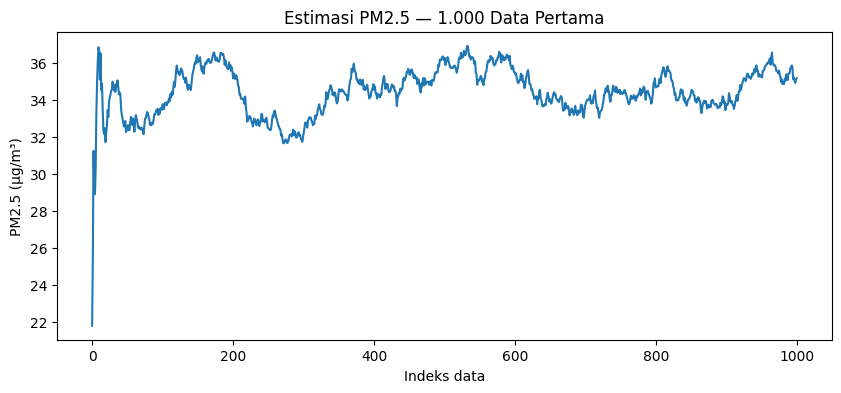

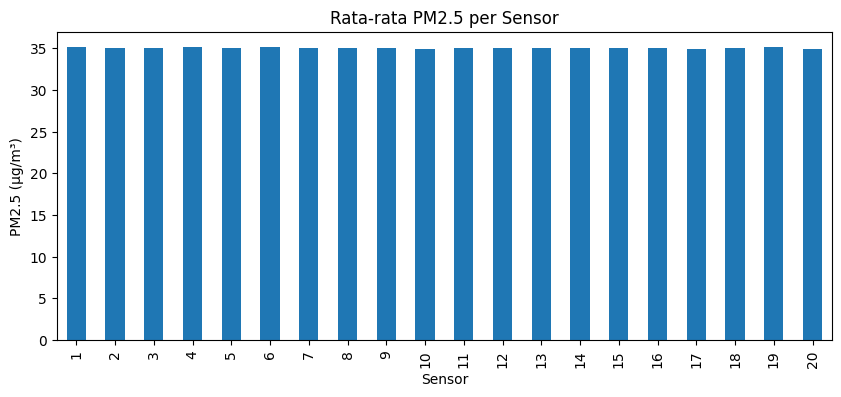

In [4]:
df["pm25_filtered"].iloc[:1000].plot(figsize=(10, 4))
plt.title("Estimasi PM2.5 — 1.000 Data Pertama")
plt.xlabel("Indeks data")
plt.ylabel("PM2.5 (µg/m³)")
plt.show()

df.groupby("sensor_id")["pm25"].mean().plot(kind="bar", figsize=(10, 4))
plt.title("Rata-rata PM2.5 per Sensor")
plt.xlabel("Sensor")
plt.ylabel("PM2.5 (µg/m³)")
plt.show()

## 5. Perbandingan Pemrosesan Serial dan Paralel

In [5]:
values = df["pm25"].to_numpy()

def calculate_chunk(chunk):
    return np.sqrt(chunk**2 + 2 * chunk + 1).mean()

# Serial
start = time.perf_counter()
serial_result = [calculate_chunk(chunk) for chunk in np.array_split(values, 8)]
serial_time = time.perf_counter() - start

# Paralel
start = time.perf_counter()
with ProcessPoolExecutor(max_workers=2) as executor:
    parallel_result = list(executor.map(calculate_chunk, np.array_split(values, 8)))
parallel_time = time.perf_counter() - start

print(f"Waktu serial:   {serial_time:.3f} detik")
print(f"Waktu paralel:  {parallel_time:.3f} detik")
print(f"Speedup:        {serial_time / parallel_time:.2f}x")
print("Hasil perhitungan konsisten:",
      np.allclose(serial_result, parallel_result))

Waktu serial:   0.013 detik
Waktu paralel:  0.125 detik
Speedup:        0.10x
Hasil perhitungan konsisten: True


## 6. Simulasi Job Queue HPC

In [6]:
jobs = pd.DataFrame({
    "job_id": ["PM25-001", "PM25-002", "PM25-003", "PM25-004"],
    "tugas": [
        "Pembersihan data sensor",
        "Perhitungan rata-rata per sensor",
        "Estimasi tren PM2.5",
        "Pembuatan visualisasi"
    ],
    "status": ["Selesai", "Selesai", "Dalam antrean", "Dalam antrean"]
})

display(jobs)

,job_id,tugas,status
0,PM25-001,Pembersihan data sensor,Selesai
1,PM25-002,Perhitungan rata-rata per sensor,Selesai
2,PM25-003,Estimasi tren PM2.5,Dalam antrean
3,PM25-004,Pembuatan visualisasi,Dalam antrean


## 7. Contoh Slurm Batch Script
Skrip berikut hanya contoh untuk cluster HPC yang sudah menggunakan Slurm. Skrip ini tidak dijalankan di Google Colab.

In [7]:
%%writefile pm25_job.slurm
#!/bin/bash
#SBATCH --job-name=pm25-analysis
#SBATCH --output=pm25-output-%j.txt
#SBATCH --time=00:10:00
#SBATCH --ntasks=1
#SBATCH --cpus-per-task=4
#SBATCH --mem=4G

module load python
python pm25_analysis.py

# Di cluster HPC, kirim pekerjaan dengan:
# sbatch pm25_job.slurm
# Periksa antrean dengan:
# squeue -u $USER

Writing pm25_job.slurm
